In [1]:
import pandas as pd
import re

# 1. Cargamos el resultado de FragPipe UNIFICADO (el que tiene la columna 'Batch')
# ¡Ojo! Pon aquí la ruta del archivo que generó el script de bash
archivo_unido = "../data/raw/todos_los_peptidos_unidos.tsv" 
df_ms = pd.read_csv(archivo_unido, sep="\t")

# 2. Extraemos los neoantígenos DIRECTAMENTE de las cabeceras del FASTA
neo_list = []
with open("../data/processed/Custom_Top1000_FragPipe.fasta", "r") as f:
    for line in f:
        if line.startswith(">sp|MUT_"):
            match = re.search(r'>sp\|MUT_(.*?)\|', line)
            if match:
                content = match.group(1)
                parts = content.split('_')
                pep = parts[-1] 
                
                if parts[0] == "SYNTH":
                    gen = "_".join(parts[1:-1])
                else:
                    gen = "_".join(parts[:-1])
                    
                neo_list.append({"Gen": gen, "Peptido_Mutado": pep})

df_neo = pd.DataFrame(neo_list).drop_duplicates()

# 3. OPTIMIZACIÓN DE BÚSQUEDA (Para que tarde 1 segundo en lugar de 30 minutos)
print("Mapeando péptidos a batches para búsqueda ultrarrápida...")
# Creamos un diccionario donde cada péptido detectado por FragPipe sabe en qué batches está
pep_to_batches = df_ms.groupby("Peptide")["Batch"].unique().to_dict()
unique_ms_peptides = list(pep_to_batches.keys())

resultados_por_batch = {}
total_unicos_encontrados = set()

print(f"Buscando {len(df_neo)} neoantígenos...")

# 4. Buscamos y clasificamos por Batch
for idx, row in df_neo.iterrows():
    gen = row["Gen"]
    neo_pep = row["Peptido_Mutado"]
    
    # Comprobamos si el neoantígeno es un "substring" de los péptidos detectados
    for ms_pep in unique_ms_peptides:
        # Hacemos check de tipo por si hay algún NaN colado
        if isinstance(ms_pep, str) and neo_pep in ms_pep:
            # Recuperamos en qué batches se detectó este péptido
            batches_donde_aparece = pep_to_batches[ms_pep]
            
            for b in batches_donde_aparece:
                if b not in resultados_por_batch:
                    resultados_por_batch[b] = set()
                resultados_por_batch[b].add(f"{gen} ({neo_pep})")
                
            total_unicos_encontrados.add(f"{gen} ({neo_pep})")

# 5. Mostramos los Resultados por Batch
print("\n" + "="*50)
print("🏆 RESUMEN DE DETECCIÓN POR BATCH 🏆")
print("="*50)

# Cogemos la lista de todos los batches que existen y los ordenamos alfabéticamente
todos_los_batches = sorted(df_ms["Batch"].unique())

for b in todos_los_batches:
    if b in resultados_por_batch and len(resultados_por_batch[b]) > 0:
        encontrados = sorted(list(resultados_por_batch[b]))
        print(f"\n📦 {b}: {len(encontrados)} neoantígenos encontrados")
        for item in encontrados:
            print(f"   - {item}")
    else:
        print(f"\n📦 {b}: ❌ Ninguno")

print("\n" + "-"*50)
print(f"Total de neoantígenos ÚNICOS encontrados en todo el estudio: {len(total_unicos_encontrados)}")
print("-"*50)

Mapeando péptidos a batches para búsqueda ultrarrápida...
Buscando 644 neoantígenos...

🏆 RESUMEN DE DETECCIÓN POR BATCH 🏆

📦 Batch_01_1: 19 neoantígenos encontrados
   - BRAF (TPQQLQAFK)
   - FCGBP (QMCGLCGNY)
   - FCGBP (QQMCGLCGNY)
   - HLA-DRB5 (SVTSLLTVEWR)
   - HLA-DRB5 (VEHPSVTSL)
   - HLA-DRB5 (VTSLLTVEW)
   - KRAS (LVVVGADGV)
   - KRAS (LVVVGADGVGK)
   - KRAS (VVGADGVGK)
   - KRAS (VVVGADGVGK)
   - POTEE (IYDGNALPH)
   - PRSS3 (EQWVVSAGHCYK)
   - PRSS3 (VPYQVSLNSG)
   - PRSS3 (VVSAGHCYK)
   - PRSS3 (WVVSAGHCY)
   - PTPRS (MTSYVVEDLK)
   - REG3A (AYGSPCYAL)
   - REG3A (GSFVSSLVR)
   - TMEM63A (QTYGAIHNI)

📦 Batch_02_1: 18 neoantígenos encontrados
   - CYP4F2 (QAFAMAEMK)
   - FCGBP (QMCGLCGNY)
   - FCGBP (QQMCGLCGNY)
   - HLA-DRB5 (SVTSLLTVEWR)
   - HLA-DRB5 (VEHPSVTSL)
   - HLA-DRB5 (VTSLLTVEW)
   - KRAS (LVVVGADGV)
   - KRAS (LVVVGADGVGK)
   - KRAS (VVGADGVGK)
   - KRAS (VVVGADGVGK)
   - MUC6 (HTTSATSSK)
   - POTEE (IYDGNALPH)
   - PRSS3 (EQWVVSAGHCYK)
   - PRSS3 (VPYQVSLNSG)


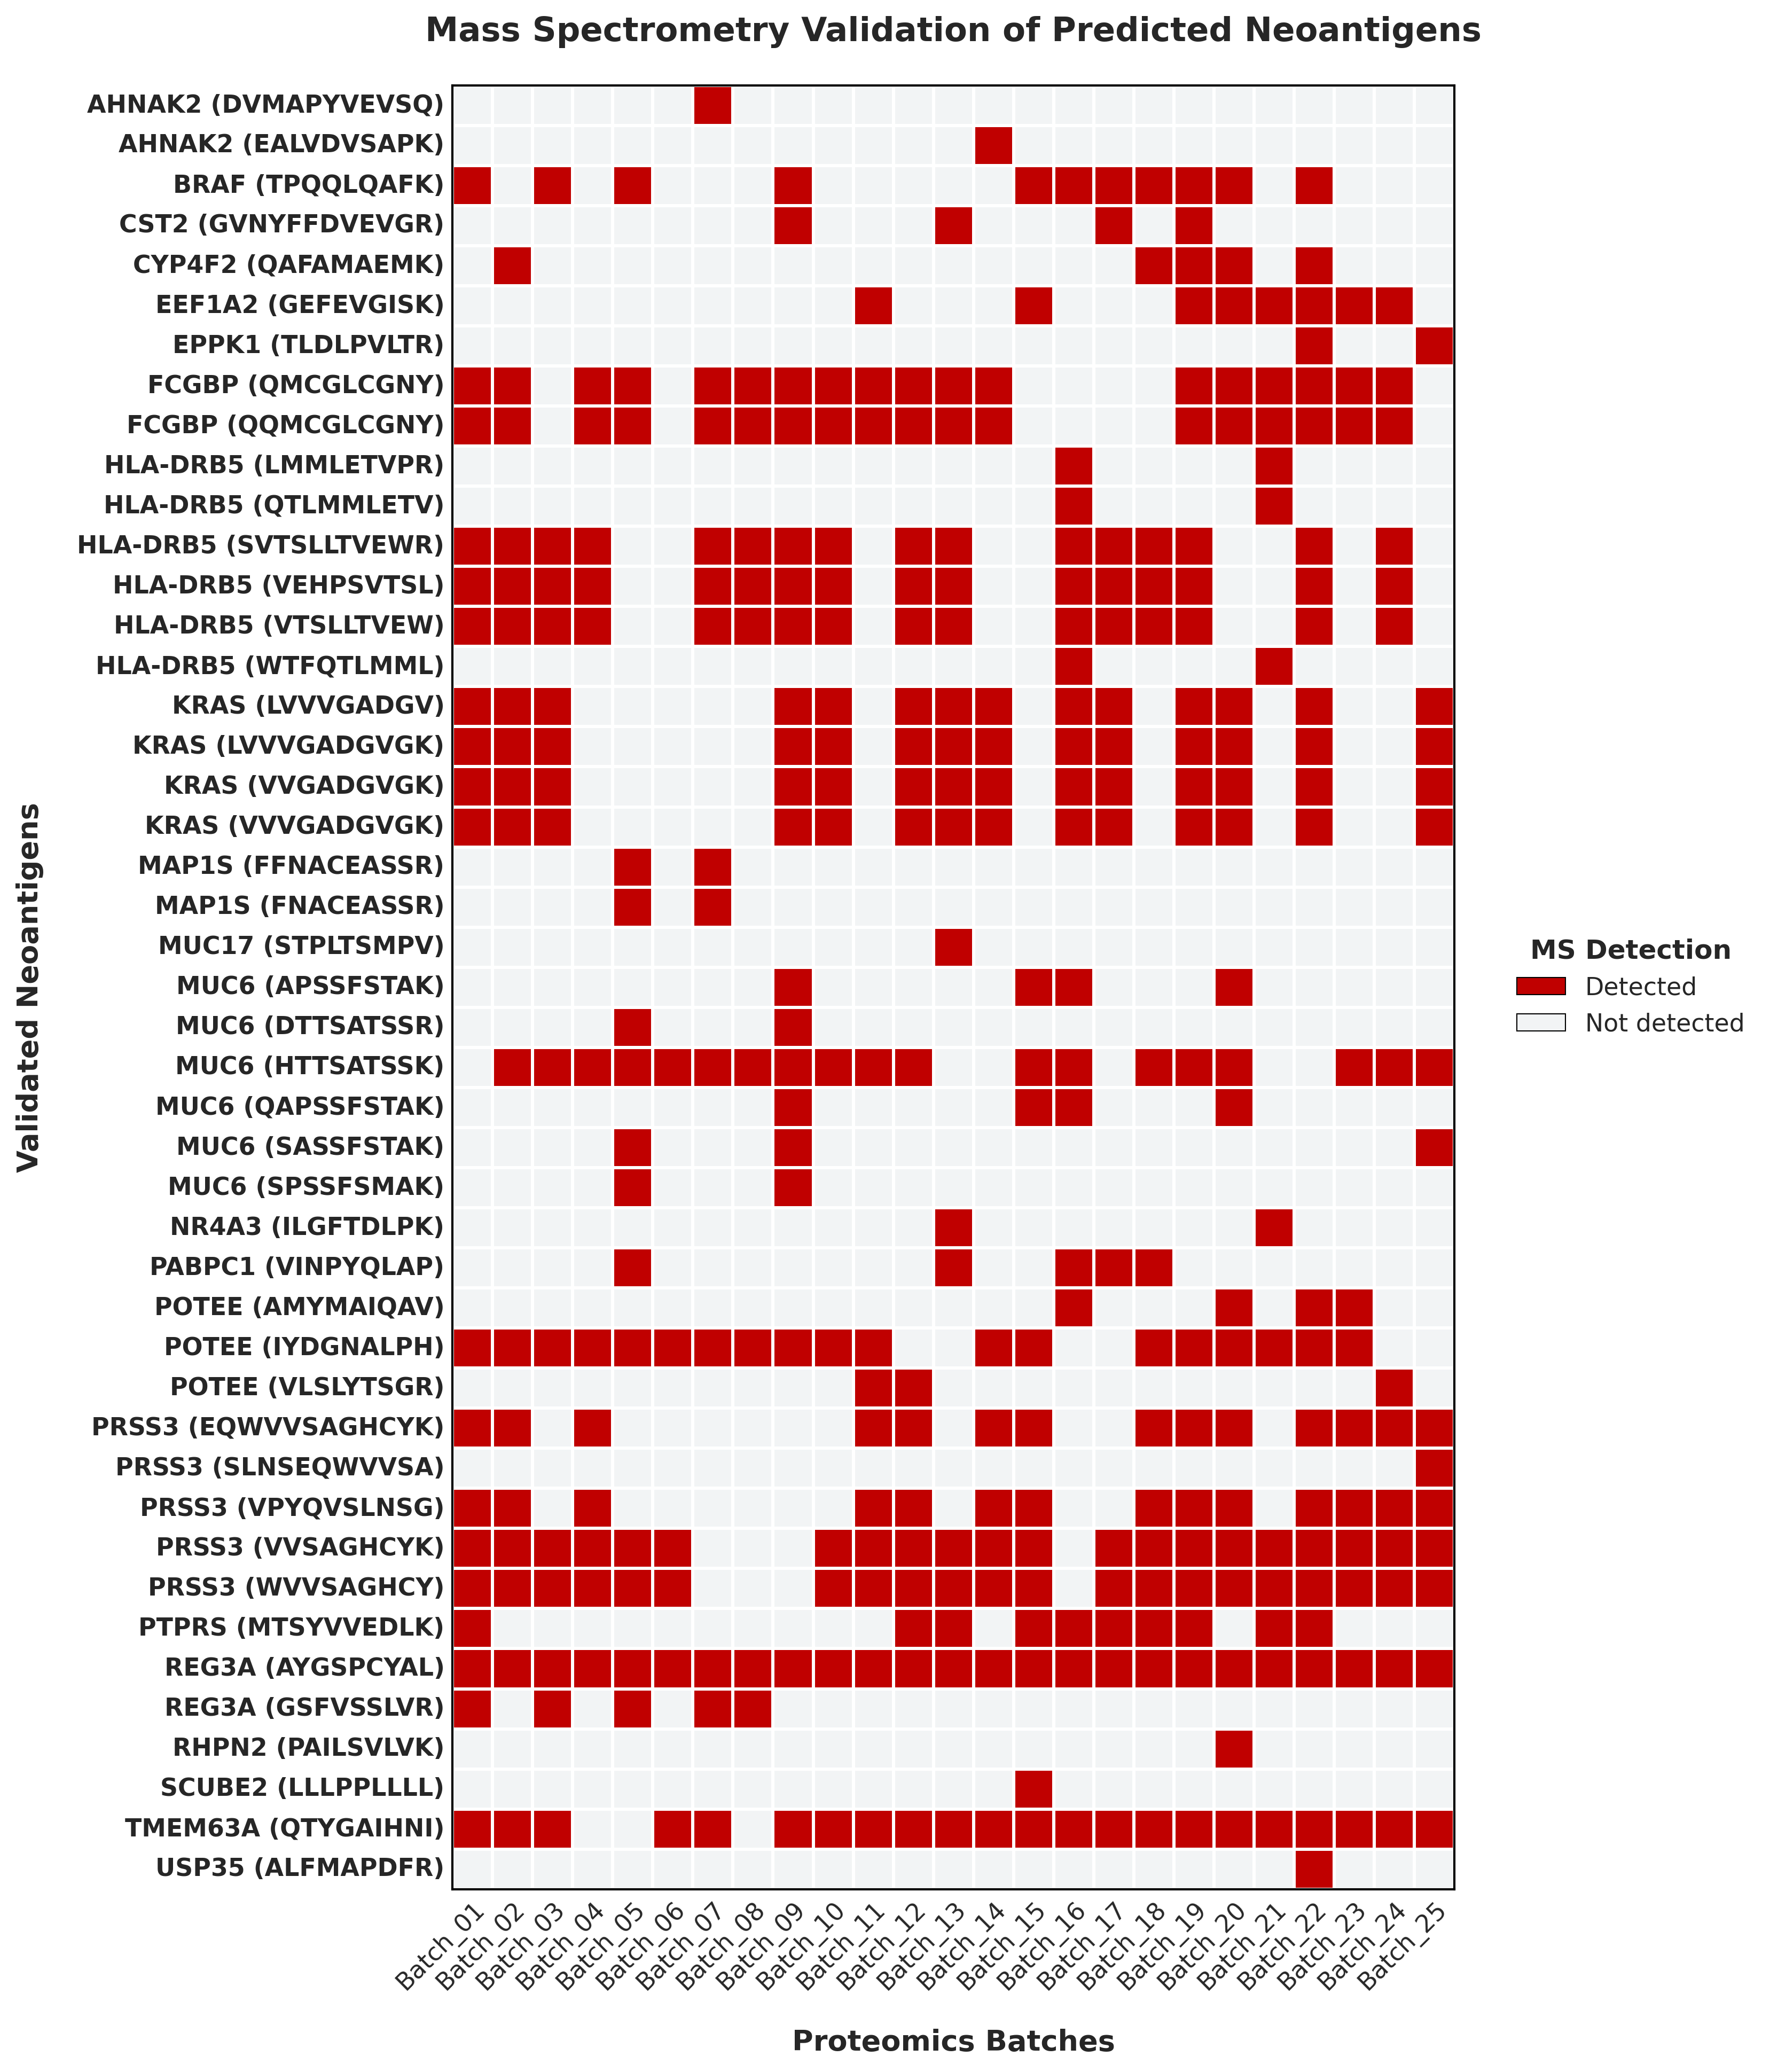

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import rcParams
from matplotlib.patches import Patch

# ==============================================================================
# CONFIGURACIÓN DE MATPLOTLIB PARA PUBLICACIÓN CIENTÍFICA
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')
rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,               
    'axes.titlesize': 15,           
    'axes.labelsize': 13,           
    'xtick.labelsize': 11,          
    'ytick.labelsize': 11,          
    'legend.fontsize': 11,           
    'figure.dpi': 300,               
    'savefig.dpi': 300               
})

# ==============================================================================
# PREPARACIÓN DE DATOS (Usando tus resultados reales)
# ==============================================================================
# 1. Obtener nombres crudos y limpios de los batches
todos_los_batches_crudos = sorted(df_ms["Batch"].unique())
# Esto convierte "Batch_01_1" -> "Batch_01" (coge las dos primeras partes separadas por "_")
todos_los_batches_limpios = ["_".join(b.split('_')[:2]) for b in todos_los_batches_crudos]

todos_los_neoantigenos = sorted(list(total_unicos_encontrados))

# 2. Inicializar la matriz con ceros
matriz_datos = np.zeros((len(todos_los_neoantigenos), len(todos_los_batches_limpios)))
df_heatmap = pd.DataFrame(matriz_datos, index=todos_los_neoantigenos, columns=todos_los_batches_limpios)

# 3. Llenar con unos (1) donde sí se detectaron
for batch_crudo, peptidos in resultados_por_batch.items():
    batch_limpio = "_".join(batch_crudo.split('_')[:2]) # Limpiamos el nombre para que coincida
    for pep in peptidos:
        df_heatmap.at[pep, batch_limpio] = 1

# ==============================================================================
# CREACIÓN DE LA FIGURA (CALCULADA DINÁMICAMENTE)
# ==============================================================================
# 1. Calculamos el tamaño exacto para que sean cuadrados perfectos sin márgenes
n_filas = len(df_heatmap.index)
n_cols = len(df_heatmap.columns)

# Le damos ~0.45 pulgadas por cada columna y fila, más un margen base
ancho_figura = max(n_cols * 0.45, 8)
alto_figura = max(n_filas * 0.45, 4)

fig, ax = plt.subplots(figsize=(ancho_figura, alto_figura))

# Colores: Gris ultra suave para "No detectado", Rojo clásico para "Detectado"
colores = ["#f2f4f5", "#c00000"] 

# Volvemos a square=True, pero como el figsize es perfecto, encajará como un guante
sns.heatmap(df_heatmap, 
            cmap=colores, 
            cbar=False, 
            linewidths=1,          # Separación blanca nítida
            linecolor='white',
            square=True,           # Cuadrados perfectos
            ax=ax)

ax.grid(False)

# 2. Añadimos un marco negro fino alrededor de la matriz (Toque de Paper)
for _, spine in ax.spines.items():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1)

# Títulos y etiquetas
ax.set_title('Mass Spectrometry Validation of Predicted Neoantigens', pad=20, fontweight='bold')
ax.set_xlabel('Proteomics Batches', labelpad=15, fontweight='bold')
ax.set_ylabel('Validated Neoantigens', labelpad=15, fontweight='bold')

# Ejes X e Y
plt.xticks(rotation=45, ha='right', rotation_mode='anchor')
plt.yticks(fontweight='bold')

# 3. Leyenda con bordes para que parezcan cajitas reales de la gráfica
legend_elements = [
    Patch(facecolor='#c00000', edgecolor='black', linewidth=0.5, label='Detected'),
    Patch(facecolor='#f2f4f5', edgecolor='black', linewidth=0.5, label='Not detected')
]

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.04, 0.5), 
          title="MS Detection", title_fontproperties={'weight':'bold'}, frameon=False)

# Guardar recortando milimétricamente el blanco sobrante
plt.tight_layout()
plt.savefig('../results/figures/proteomics_characterization/Figure_OncoPrint_Patients.png', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
import pandas as pd
import numpy as np

# 1. Recuperamos los péptidos validados directamente de la celda anterior
peptidos_validados = [item.split(" (")[1].replace(")", "") for item in total_unicos_encontrados]
neo_dict = dict(zip(df_neo['Peptido_Mutado'], df_neo['Gen']))

# 2. CARGAMOS EL MAPA DE PACIENTES PARA RECUPERAR EL BATCH
# Esto creará un diccionario tipo {'CPT0237840004': 'Batch_01', ...}
mapa_pacientes = {}
con_errores = 0

with open("../data/interim/proteomal/Mapa_Pacientes_CPTAC.txt", "r") as f:
    for linea in f:
        if "|" in linea:
            partes = linea.split("|")
            # Extraemos el "01" de "./01CPTAC_PDA_Proteome_JHU_20191125/..."
            try:
                carpeta = partes[0].strip().split("/")[1]
                batch_num = carpeta[:2] 
                
                # Extraemos el código de paciente "CPT0237840004" de "127C CPT0237840004"
                paciente = partes[1].strip().split()[1]
                
                mapa_pacientes[paciente] = f"Batch_{batch_num}"
            except:
                con_errores += 1

print(f"Mapa cargado: {len(mapa_pacientes)} pacientes vinculados a sus batches.")

# 3. Cargar abundancias (Con low_memory=False para evitar el warning de Pandas)
ruta_abundance = "../data/raw/abundance_peptide_MD.tsv"
print("Cargando matriz global de abundancias...")
df_ab = pd.read_csv(ruta_abundance, sep="\t", low_memory=False)

# 4. Filtrar solo filas con nuestros neoantígenos
mascara = df_ab['Peptide'].apply(lambda x: any(neo in str(x) for neo in peptidos_validados))
df_filtrado = df_ab[mascara].copy()

# 5. Seleccionar columnas de pacientes y pivotar la tabla (Melt)
ignorar = ['Index', 'Gene', 'ProteinID', 'SequenceWindow', 'Start', 'End', 
           'MaxPepProb', 'Spectrum Number', 'Protein', 'Entry Name', 
           'Protein Description', 'Mapped Genes', 'Mapped Proteins', 
           'ReferenceIntensity', 'pool', 'qc', 'reference', 'ref', 'korean']

# ¡AÑADIDO: and col != 'Peptide' para evitar duplicados!
columnas_pacientes = [col for col in df_filtrado.columns 
                      if not any(ign.lower() in str(col).lower() for ign in ignorar) 
                      and col != 'Peptide']

columnas_finales = ['Peptide'] + columnas_pacientes

df_pacientes = df_filtrado[columnas_finales].copy()

# Ahora el melt funcionará perfecto porque solo hay un 'Peptide'
df_melt = pd.melt(df_pacientes, id_vars=['Peptide'], var_name='Paciente', value_name='Abundancia_TMT')

# 6. Asignar Neoantígeno, Gen y BATCH
def extraer_neo(pep_largo):
    for neo in peptidos_validados:
        if neo in str(pep_largo):
            return neo
    return pep_largo

df_melt['Neoantigeno'] = df_melt['Peptide'].apply(extraer_neo)
df_melt['Gen'] = df_melt['Neoantigeno'].map(neo_dict)

# Mapeamos usando el diccionario que creamos con tu TXT
df_melt['Batch'] = df_melt['Paciente'].map(mapa_pacientes)

# 7. Nos quedamos SOLO con los pacientes positivos (> 0) y convertimos a número seguro
df_melt['Abundancia_TMT'] = pd.to_numeric(df_melt['Abundancia_TMT'], errors='coerce')
df_positivos = df_melt[(df_melt['Abundancia_TMT'] > 0) & (df_melt['Abundancia_TMT'].notna())].copy()

# Ordenar y colocar las columnas
df_positivos = df_positivos.sort_values(by=['Gen', 'Abundancia_TMT'], ascending=[True, False])
df_positivos = df_positivos[['Gen', 'Neoantigeno', 'Batch', 'Paciente', 'Abundancia_TMT']]

# 8. Mostrar e imprimir
print("\n" + "="*70)
print("🧬 PACIENTES POSITIVOS PARA NEOANTÍGENOS (Abundancia TMT) 🧬")
print("="*70)
display(df_positivos)

df_positivos.to_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_por_Paciente_CPTAC.csv", index=False)

Mapa cargado: 235 pacientes vinculados a sus batches.
Cargando matriz global de abundancias...

🧬 PACIENTES POSITIVOS PARA NEOANTÍGENOS (Abundancia TMT) 🧬


,Gen,Neoantigeno,Batch,Paciente,Abundancia_TMT
2269,AHNAK2,DVMAPYVEVSQ,Batch_07,CPT0109010004,13.464421
2161,AHNAK2,DVMAPYVEVSQ,Batch_07,CPT0174800003,13.371905
2377,AHNAK2,DVMAPYVEVSQ,Batch_07,CPT0108410003,13.254943
2197,AHNAK2,DVMAPYVEVSQ,Batch_07,CPT0108400003,13.185973
2125,AHNAK2,DVMAPYVEVSQ,Batch_07,CPT0091680003,13.160633
...,...,...,...,...,...
7512,USP35,ALFMAPDFR,Batch_22,CPT0241320005,11.178103
7584,USP35,ALFMAPDFR,Batch_22,CPT0087890004,10.236038
7476,USP35,ALFMAPDFR,Batch_22,CPT0127270003,9.739108
7296,USP35,ALFMAPDFR,Batch_22,CPT0227930004,9.731447


In [4]:
import pandas as pd
from scipy.stats import zscore

# 1. Cargamos tus 2100 resultados
df = pd.read_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_por_Paciente_CPTAC.csv")

# 2. Calcular el Z-Score por Batch y Neoantígeno
# Esto nos dirá qué paciente "sobresale" del resto de sus compañeros en el mismo tubo
df['Z_Score'] = df.groupby(['Batch', 'Neoantigeno'])['Abundancia_TMT'].transform(lambda x: zscore(x, ddof=1))

# 3. Filtrar los verdaderos positivos
# Un Z-score > 1.5 o 2.0 significa que ese paciente tiene una señal muy superior al ruido de fondo
umbral_z = 1.5 
df_reales = df[df['Z_Score'] >= umbral_z].copy()

# Ordenamos por la fuerza de la señal
df_reales = df_reales.sort_values(by=['Neoantigeno', 'Z_Score'], ascending=[True, False])

print("\n" + "="*70)
print(f"🎯 PACIENTES CONFIRMADOS (Z-Score > {umbral_z}) 🎯")
print("="*70)
print(f"Tras limpiar el ruido, nos quedan {len(df_reales)} detecciones reales.\n")

display(df_reales)

df_reales.to_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_Confirmados_AltaConfianza.csv", index=False)


🎯 PACIENTES CONFIRMADOS (Z-Score > 1.5) 🎯
Tras limpiar el ruido, nos quedan 162 detecciones reales.



,Gen,Neoantigeno,Batch,Paciente,Abundancia_TMT,Z_Score
954,MUC6,APSSFSTAK,Batch_09,CPT0264180003,22.546239,2.305883
969,MUC6,APSSFSTAK,Batch_16,CPT0221470005,20.668360,2.012409
979,MUC6,APSSFSTAK,Batch_20,CPT0064570003,20.225667,1.522760
1585,REG3A,AYGSPCYAL,Batch_10,CPT0077880003,30.112555,2.669525
1586,REG3A,AYGSPCYAL,Batch_06,CPT0086210003,29.980844,2.543357
...,...,...,...,...,...,...
1329,PRSS3,WVVSAGHCY,Batch_05,CPT0162600005,27.075632,1.762857
1286,PRSS3,WVVSAGHCY,Batch_11,CPT0248440003,28.769703,1.686568
1276,PRSS3,WVVSAGHCY,Batch_03,CPT0239140004,29.739897,1.631719
1291,PRSS3,WVVSAGHCY,Batch_22,CPT0127290003,28.404372,1.593326


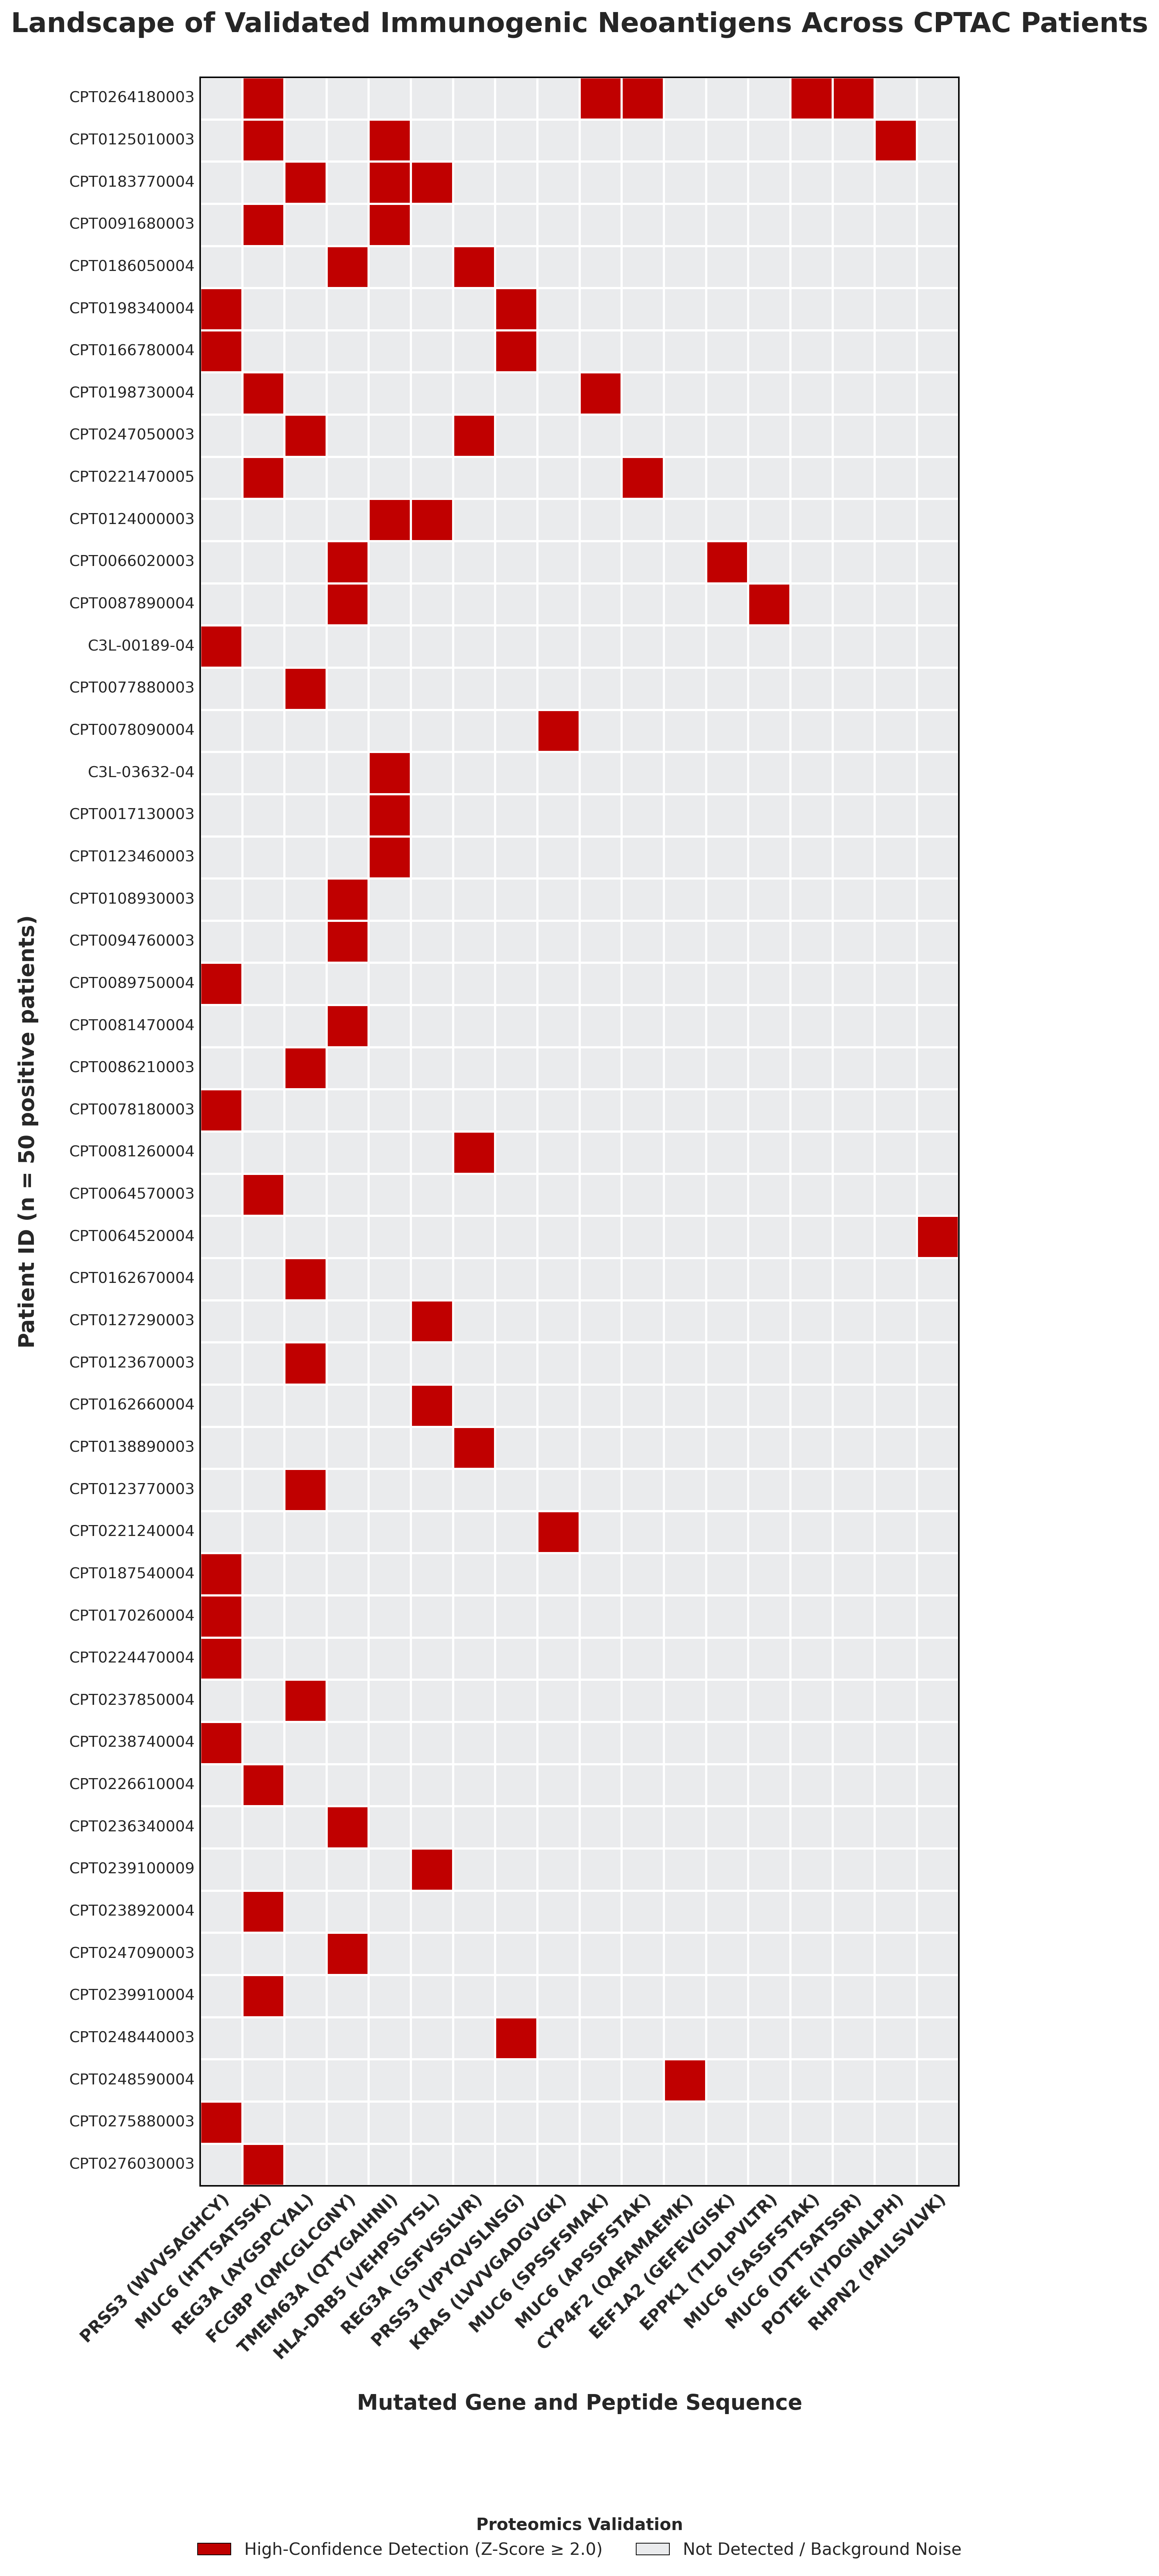

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import zscore
from matplotlib import rcParams
from matplotlib.patches import Patch

# ==============================================================================
# 1. CARGA Y PREPARACIÓN DE DATOS
# ==============================================================================
df = pd.read_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_por_Paciente_CPTAC.csv")
df['Z_Score'] = df.groupby(['Batch', 'Neoantigeno'])['Abundancia_TMT'].transform(lambda x: zscore(x, ddof=1) if len(x)>1 else 0)

umbral = 2.0
df_pos = df[df['Z_Score'] >= umbral].copy()

# Crear Label y Matriz
df_pos['Label'] = df_pos['Gen'] + " (" + df_pos['Neoantigeno'] + ")"
pivot_df = pd.pivot_table(df_pos, values='Z_Score', index='Label', columns='Paciente', aggfunc=lambda x: 1, fill_value=0)

# Ordenar (OncoPrint style) por mayor frecuencia
row_order = pivot_df.sum(axis=1).sort_values(ascending=False).index
col_order = pivot_df.sum(axis=0).sort_values(ascending=False).index
pivot_df = pivot_df.loc[row_order, col_order]

# ¡AQUÍ ESTÁ LA MAGIA!: Transponemos la matriz para intercambiar ejes
pivot_df = pivot_df.T 

# ==============================================================================
# 2. CONFIGURACIÓN PARA PAPER
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')
rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'figure.dpi': 300,
    'savefig.dpi': 300
})

# ==============================================================================
# 3. MATEMÁTICAS DINÁMICAS (AHORA VERTICAL)
# ==============================================================================
# Ahora las columnas son los neoantígenos (~17) y las filas son los pacientes (~52)
num_cols = len(pivot_df.columns)
num_rows = len(pivot_df.index)

# Ajustamos las proporciones. Más alto que ancho.
ancho_figura = max(num_cols * 0.45 + 5, 8)  
alto_figura = max(num_rows * 0.35 + 6, 10) 

fig, ax = plt.subplots(figsize=(ancho_figura, alto_figura))

colores = ["#eaebed", "#c00000"] # Gris suave y Rojo oscuro

# ==============================================================================
# 4. DIBUJAR EL MAPA
# ==============================================================================
sns.heatmap(pivot_df, 
            cmap=colores, 
            cbar=False, 
            linewidths=1, 
            linecolor='white',
            square=True,           
            ax=ax)

# Marco negro exterior
for _, spine in ax.spines.items():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1)

# Textos (Intercambiados)
ax.set_title('Landscape of Validated Immunogenic Neoantigens Across CPTAC Patients', pad=30, fontweight='bold', fontsize=18)
ax.set_xlabel('Mutated Gene and Peptide Sequence', labelpad=20, fontweight='bold', fontsize=14)
ax.set_ylabel(f'Patient ID (n = {num_rows} positive patients)', labelpad=20, fontweight='bold', fontsize=14)

# ALINEACIÓN DE LOS EJES
# Eje X: Neoantígenos (nombres largos), rotamos a 45º anclados
plt.xticks(rotation=45, ha='right', rotation_mode='anchor', fontsize=11, fontweight='bold')
# Eje Y: Pacientes (códigos cortos), rectos para que se lean bien como una lista
plt.yticks(rotation=0, fontsize=10)

# Leyenda reposicionada (la bajamos un poco más para que no se superponga con el eje X largo)
legend_elements = [
    Patch(facecolor='#c00000', edgecolor='black', linewidth=0.5, label='High-Confidence Detection (Z-Score ≥ 2.0)'),
    Patch(facecolor='#eaebed', edgecolor='black', linewidth=0.5, label='Not Detected / Background Noise')
]

ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.15), 
          title="Proteomics Validation", title_fontproperties={'weight':'bold'}, frameon=False, ncol=2, fontsize=11)

# Guardar
plt.tight_layout()
plt.savefig('../results/figures/proteomics_characterization/Figure_OncoPrint_Patients_Transposed.png', dpi=300, bbox_inches='tight')
plt.show()

### Bubble Dot Plot

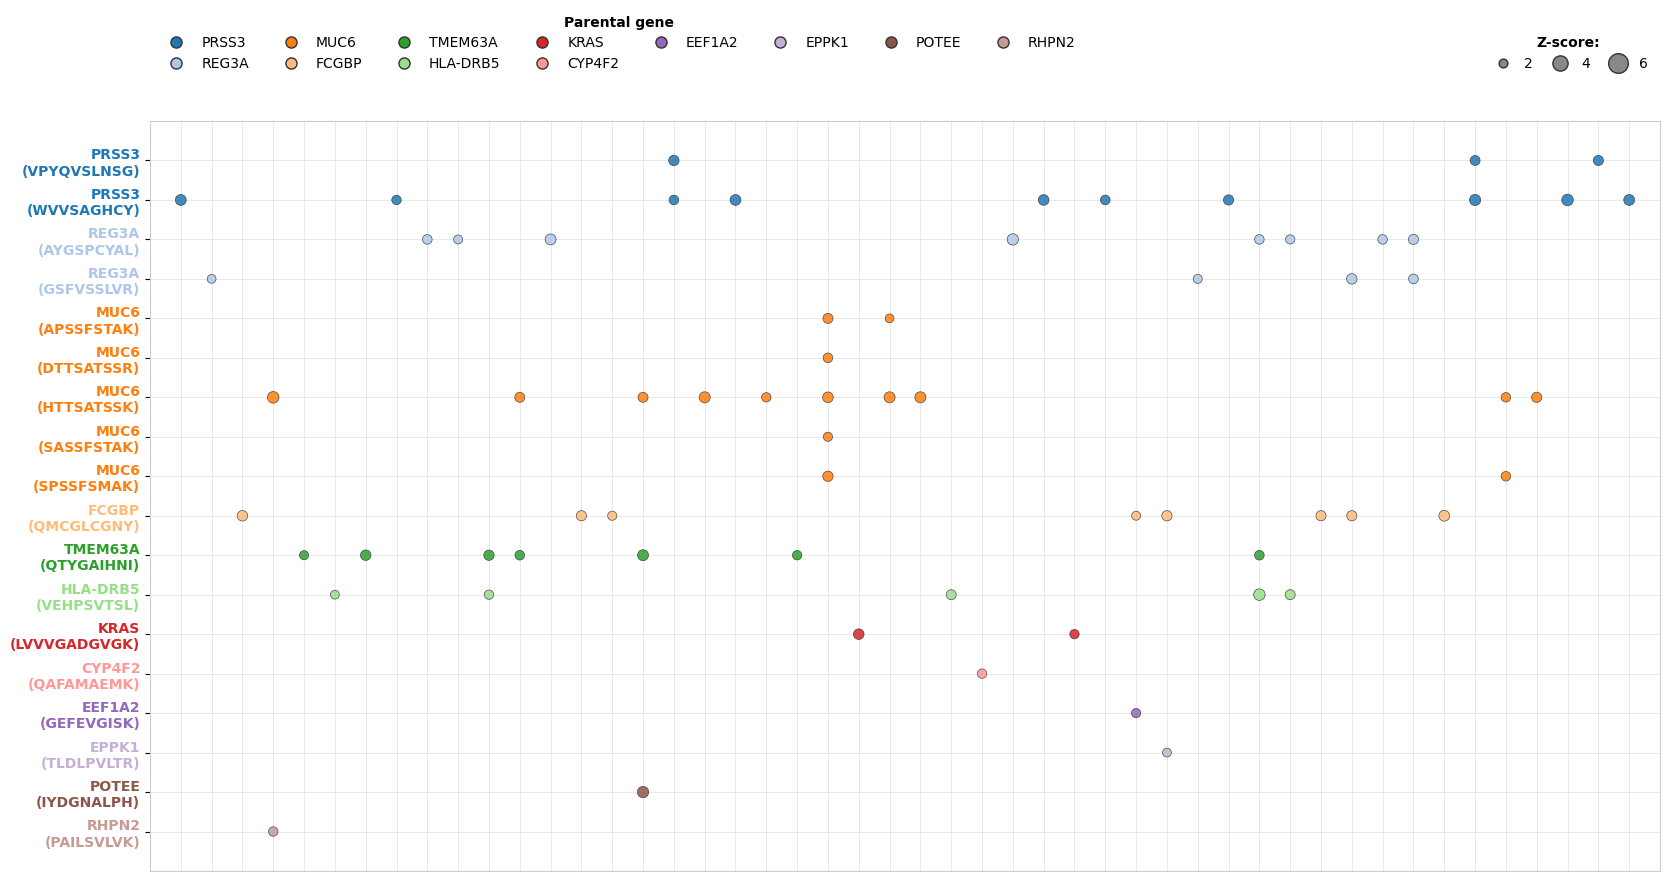

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from matplotlib import rcParams

# ==============================================================================
# 1. CARGA DE DATOS PROTEÓMICOS Y CÁLCULO DE Z-SCORE
# ==============================================================================
df = pd.read_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_por_Paciente_CPTAC.csv")

# Calculamos Z-Score y filtramos señales fuertes (Z >= 2.0)
df['Z_Score'] = df.groupby(['Batch', 'Neoantigeno'])['Abundancia_TMT'].transform(
    lambda x: zscore(x, ddof=1) if len(x) > 1 else 0
)
df_pos = df[df['Z_Score'] >= 2.0].copy()

# Creamos la etiqueta que se mostrará en el Eje Y: Gen \n (Péptido)
df_pos['Label'] = df_pos['Gen'] + "\n(" + df_pos['Neoantigeno'] + ")"

# ==============================================================================
# 2. MAPEO DE PACIENTES ("La Piedra Rosetta")
# ==============================================================================
# Aseguramos que usamos los IDs oficiales (C3L-...) si están disponibles
ruta_mapping = "../data/interim/proteomal/case_aliquot_mapping.csv"
df_map = pd.read_csv(ruta_mapping)

diccionario_prefijos = {}
for _, row in df_map.iterrows():
    case_id = row['case_id']
    aliquot = str(row['aliquot_submitter_id'])
    if aliquot.startswith('CPT'):
        diccionario_prefijos[aliquot[:10]] = case_id

def traducir_paciente(paciente_raw):
    paciente_str = str(paciente_raw)
    if paciente_str.startswith('CPT'):
        prefijo = paciente_str[:10]
        if prefijo in diccionario_prefijos:
            return diccionario_prefijos[prefijo]
    partes = paciente_str.split('-')
    if len(partes) >= 3 and partes[0] in ['C3L', 'C3N']:
        return f"{partes[0]}-{partes[1]}"
    return paciente_raw 

df_pos['Paciente_ID'] = df_pos['Paciente'].apply(traducir_paciente)

# ==============================================================================
# 3. ORDENACIÓN (POR FRECUENCIA) Y COORDENADAS
# ==============================================================================
# 1. Calculamos en cuántos pacientes distintos aparece cada Gen
frecuencia_genes = df_pos.groupby('Gen')['Paciente_ID'].nunique()
df_pos['Frecuencia_Gen'] = df_pos['Gen'].map(frecuencia_genes)

# 2. Ordenamos el Eje Y (Genes) poniendo los más frecuentes arriba
df_pos = df_pos.sort_values(by=['Frecuencia_Gen', 'Gen', 'Label'], ascending=[False, True, True])
y_labels = df_pos['Label'].unique()

# 3. Ordenamos el Eje X (Pacientes) alfabéticamente
x_labels = sorted(df_pos['Paciente_ID'].unique())

# 4. Mapeo de coordenadas X e Y
x_map = {val: i for i, val in enumerate(x_labels)}
y_map = {val: i for i, val in enumerate(y_labels)}

df_pos['x_coord'] = df_pos['Paciente_ID'].map(x_map)
df_pos['y_coord'] = df_pos['Label'].map(y_map)

# ==============================================================================
# 4. PALETA DE COLORES Y TEMA
# ==============================================================================
plt.style.use('default')
rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

genes_unicos = df_pos['Gen'].unique()
colores_genes = sns.color_palette("tab20", len(genes_unicos))
paleta_genes = {gen: colores_genes[i] for i, gen in enumerate(genes_unicos)}

df_pos['Dot_Color'] = df_pos['Gen'].map(paleta_genes)

# ==============================================================================
# 5. CONSTRUCCIÓN DE LA FIGURA PRINCIPAL
# ==============================================================================
ancho = max(len(x_labels) * 0.35, 12)
# El alto es un poco menor porque ya no hay barras en la parte inferior
alto = max(len(y_labels) * 0.5, 6) 
fig, ax = plt.subplots(figsize=(ancho, alto))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

SIZE_FACTOR = 40
# Scatter Plot (El DotPlot)
ax.scatter(
    x=df_pos['x_coord'], y=df_pos['y_coord'],
    s=(df_pos['Z_Score'] - 1) * SIZE_FACTOR,
    c=df_pos['Dot_Color'],
    alpha=0.85, edgecolors='#333333', linewidth=0.5
)

# ==============================================================================
# 6. FORMATO DE EJES Y CUADRÍCULA
# ==============================================================================
# Eje Y: Colorear el texto de cada gen con el mismo color que sus puntos
ax.set_yticks(range(len(y_labels)))
ax.set_yticklabels(y_labels)
for i, tick_label in enumerate(ax.get_yticklabels()):
    gen_name = y_labels[i].split('\n')[0]
    tick_label.set_color(paleta_genes[gen_name])
    tick_label.set_fontweight('bold')

# Eje X: Sin etiquetas para emular el pantallazo (o podrías poner x_labels si quieres ver el ID)
ax.set_xticks(range(len(x_labels)))
ax.set_xticklabels([]) 
ax.tick_params(axis='x', which='both', length=0) 

# Invertir eje Y (para que los más frecuentes estén arriba) y ajustar límites
ax.invert_yaxis()
ax.set_xlim(-1, len(x_labels))
ax.set_ylim(len(y_labels), -1) 

# Cuadrícula de fondo
ax.grid(True, color='#e0e0e0', linestyle='-', linewidth=0.5, zorder=0)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color('#cccccc')

# ==============================================================================
# 7. LEYENDAS (Solo Z-Score y Genes)
# ==============================================================================
# A. Leyenda de Z-Score (Arriba a la derecha)
z_vals = [2, 4, 6]
legend_size = [plt.Line2D([0], [0], marker='o', color='white', markerfacecolor='#888888', 
                          markersize=np.sqrt((z-1) * SIZE_FACTOR), markeredgecolor='#333333', label=f"{z}") 
               for z in z_vals]
leg_z = ax.legend(handles=legend_size, title="Z-score:", loc='lower right', 
                  bbox_to_anchor=(1.0, 1.05), # Posición ajustada
                  ncol=len(z_vals), frameon=False, columnspacing=1, handletextpad=0.5, title_fontproperties={'weight':'bold'})
ax.add_artist(leg_z)

# B. Leyenda de Genes (Arriba a la izquierda)
leg_genes_handles = [plt.Line2D([0], [0], marker='o', color='white', markerfacecolor=color, markersize=8, 
                                markeredgecolor='#333333', label=label) 
                     for label, color in paleta_genes.items()]
num_cols = max(1, min(8, len(paleta_genes))) 
leg_genes = ax.legend(handles=leg_genes_handles, title="Parental gene", loc='lower left', 
                      bbox_to_anchor=(0.0, 1.05), # Posición ajustada
                      ncol=num_cols, frameon=False, title_fontproperties={'weight':'bold'})

# ==============================================================================
# GUARDADO
# ==============================================================================
plt.tight_layout()
# Aseguramos un poco de espacio extra arriba para las leyendas
plt.subplots_adjust(top=0.85)

plt.savefig('../results/figures/proteomics_characterization/Figure_Interactive_DotPlot_Clean.png', 
            dpi=300, 
            bbox_inches='tight', 
            bbox_extra_artists=(leg_z, leg_genes)) # Evita que se recorten
plt.show()